In [ ]:
import pandas as pd

# تحميل البيانات
df = pd.read_csv("/content/Data.csv")

# نضرة عامة
print(df.info())
print(df.describe())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199999 entries, 0 to 199998
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                199999 non-null  int64  
 1   user_id                 199999 non-null  int64  
 2   order_number            199999 non-null  int64  
 3   order_dow               199999 non-null  int64  
 4   order_hour_of_day       199999 non-null  int64  
 5   days_since_prior_order  186694 non-null  float64
 6   product_id              199999 non-null  int64  
 7   add_to_cart_order       199999 non-null  int64  
 8   reordered               199999 non-null  int64  
 9   department_id           199999 non-null  int64  
 10  department              199999 non-null  object 
 11  product_name            199999 non-null  object 
dtypes: float64(1), int64(9), object(2)
memory usage: 18.3+ MB
None
           order_id        user_id   order_number      order_dow 

In [ ]:
# معالجة القيم المفقودة
df['days_since_prior_order'] = df['days_since_prior_order'].fillna(0)  # استبدال القيم المفقودة بـ 0

# التأكد من أن القيم المفقودة قد تمت معالجتها
print("عدد القيم المفقودة بعد المعالجة:")
print(df.isnull().sum())


عدد القيم المفقودة بعد المعالجة:
order_id                  0
user_id                   0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
product_id                0
add_to_cart_order         0
reordered                 0
department_id             0
department                0
product_name              0
dtype: int64


<ipython-input-4-9c64cccb7695>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='order_hour_of_day', data=df, palette='viridis')


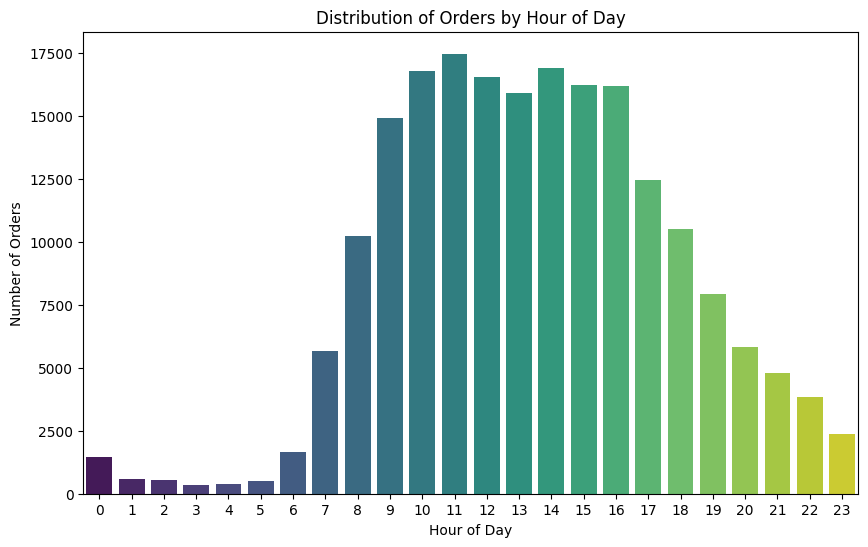

<ipython-input-4-9c64cccb7695>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='order_dow', data=df, palette='coolwarm')


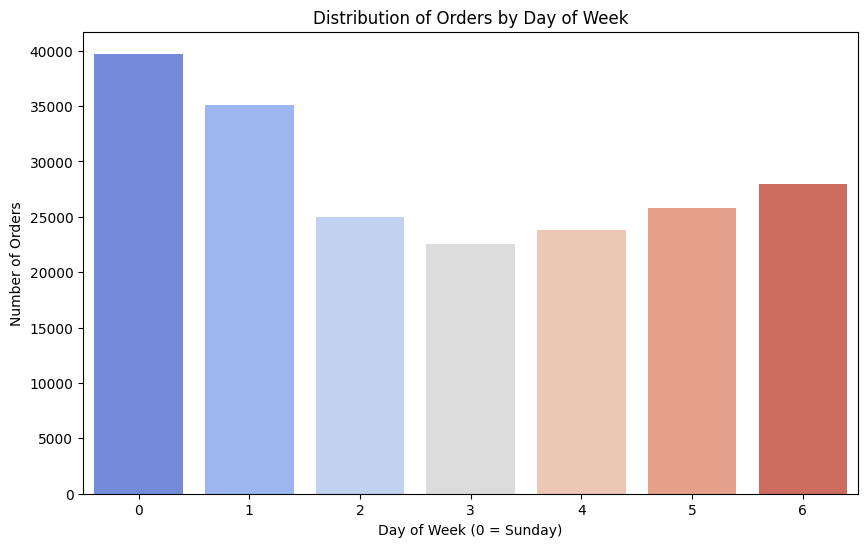

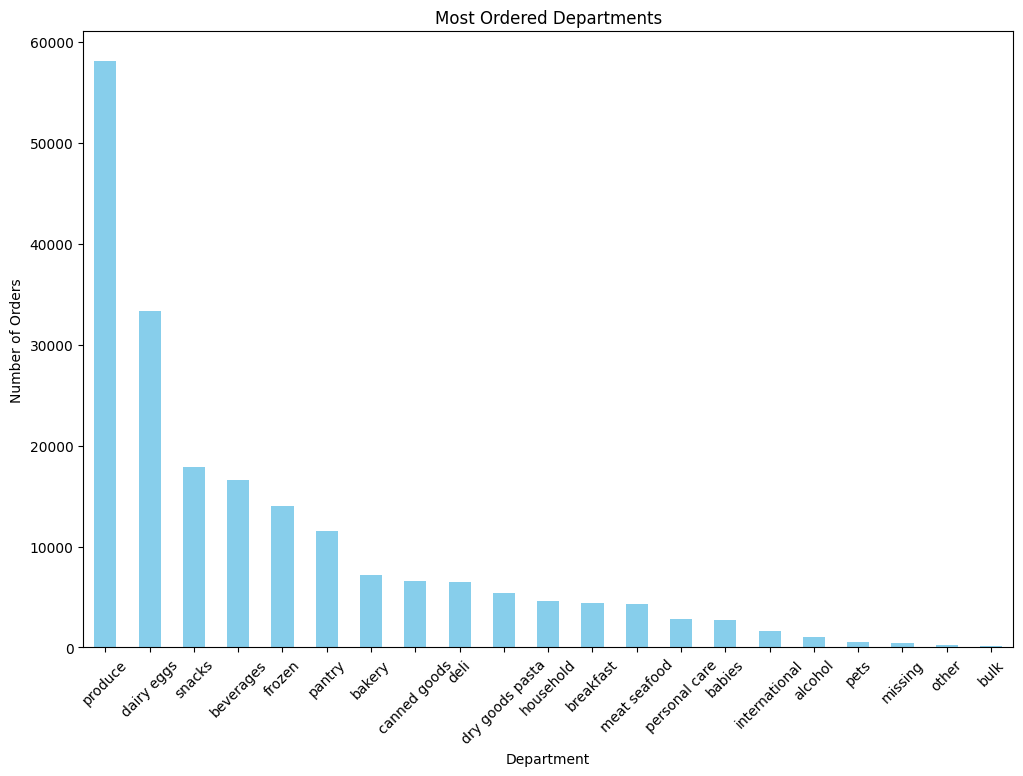

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# توزيع الطلبات حسب وقت اليوم
plt.figure(figsize=(10, 6))
sns.countplot(x='order_hour_of_day', data=df, palette='viridis')
plt.title('Distribution of Orders by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Orders')
plt.show()

# توزيع الطلبات حسب أيام الأسبوع
plt.figure(figsize=(10, 6))
sns.countplot(x='order_dow', data=df, palette='coolwarm')
plt.title('Distribution of Orders by Day of Week')
plt.xlabel('Day of Week (0 = Sunday)')
plt.ylabel('Number of Orders')
plt.show()

# الأقسام الأكثر طلبًا
plt.figure(figsize=(12, 8))
df['department'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Most Ordered Departments')
plt.xlabel('Department')
plt.ylabel('Number of Orders')
plt.xticks(rotation=45)
plt.show()


In [ ]:
from sklearn.preprocessing import LabelEncoder

# تحويل الأعمدة النصية إلى أرقام باستخدام LabelEncoder
label_encoder = LabelEncoder()
df['department'] = label_encoder.fit_transform(df['department'])
df['product_name'] = label_encoder.fit_transform(df['product_name'])

# حذف الأعمدة غير المفيدة للنمذجة
df = df.drop(columns=['order_id', 'user_id'])

# نظرة على البيانات بعد المعالجة
print(df.head())


   order_number  order_dow  order_hour_of_day  days_since_prior_order  \
0             1          2                 18                     0.0   
1             1          2                 18                     0.0   
2             1          2                 18                     0.0   
3             1          2                 18                     0.0   
4             1          2                 18                     0.0   

   product_id  add_to_cart_order  reordered  department_id  department  \
0          17                  1          0             13          16   
1          91                  2          0             16           7   
2          36                  3          0             16           7   
3          83                  4          0              4          19   
4          83                  5          0              4          19   

   product_name  
0             6  
1           119  
2            17  
3            53  
4            53  


In [ ]:
# التحقق من الأعمدة الموجودة
print(df.columns)

# حذف الأعمدة إذا كانت موجودة
columns_to_drop = ['order_id', 'user_id']
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])

# نظرة على البيانات بعد المعالجة
print(df.head())


Index(['order_number', 'order_dow', 'order_hour_of_day',
       'days_since_prior_order', 'product_id', 'add_to_cart_order',
       'reordered', 'department_id', 'department', 'product_name'],
      dtype='object')
   order_number  order_dow  order_hour_of_day  days_since_prior_order  \
0             1          2                 18                     0.0   
1             1          2                 18                     0.0   
2             1          2                 18                     0.0   
3             1          2                 18                     0.0   
4             1          2                 18                     0.0   

   product_id  add_to_cart_order  reordered  department_id  department  \
0          17                  1          0             13          16   
1          91                  2          0             16           7   
2          36                  3          0             16           7   
3          83                  4          0       

In [ ]:
# ترميز العمود 'department' و 'product_name'
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

# تحويل القيم النصية إلى عددية
df['department_encoded'] = label_encoder.fit_transform(df['department'])
df['product_name_encoded'] = label_encoder.fit_transform(df['product_name'])

# عرض إطار البيانات بعد التعديلات
print(df.head())


   order_number  order_dow  order_hour_of_day  days_since_prior_order  \
0             1          2                 18                     0.0   
1             1          2                 18                     0.0   
2             1          2                 18                     0.0   
3             1          2                 18                     0.0   
4             1          2                 18                     0.0   

   product_id  add_to_cart_order  reordered  department_id  department  \
0          17                  1          0             13          16   
1          91                  2          0             16           7   
2          36                  3          0             16           7   
3          83                  4          0              4          19   
4          83                  5          0              4          19   

   product_name  department_encoded  product_name_encoded  
0             6                  16                     

<Figure size 1200x800 with 0 Axes>

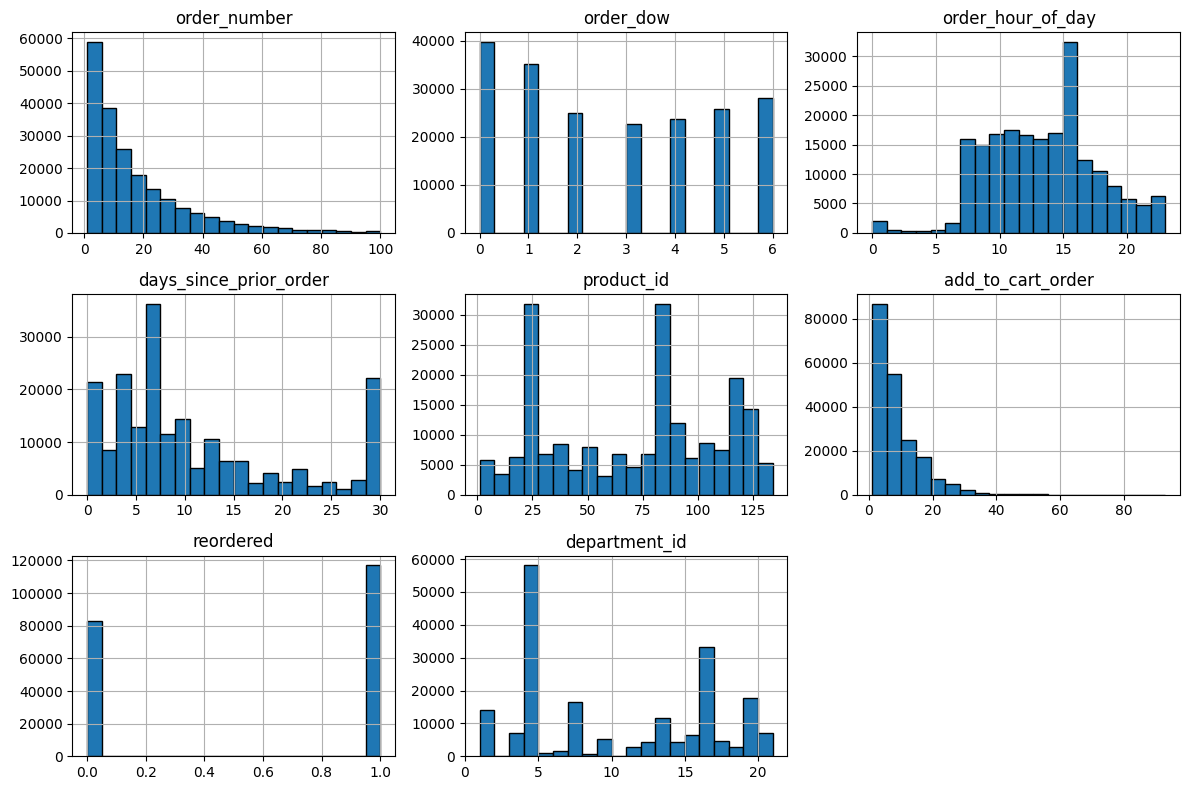

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# تحديد الأبعاد بشكل أكبر للرسومات البيانية
plt.figure(figsize=(12, 8))

# رسم التوزيع لكل من الأعمدة الرقمية
df[['order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order', 'product_id',
    'add_to_cart_order', 'reordered', 'department_id']].hist(bins=20, edgecolor='black', figsize=(12, 8))

plt.tight_layout()
plt.show()


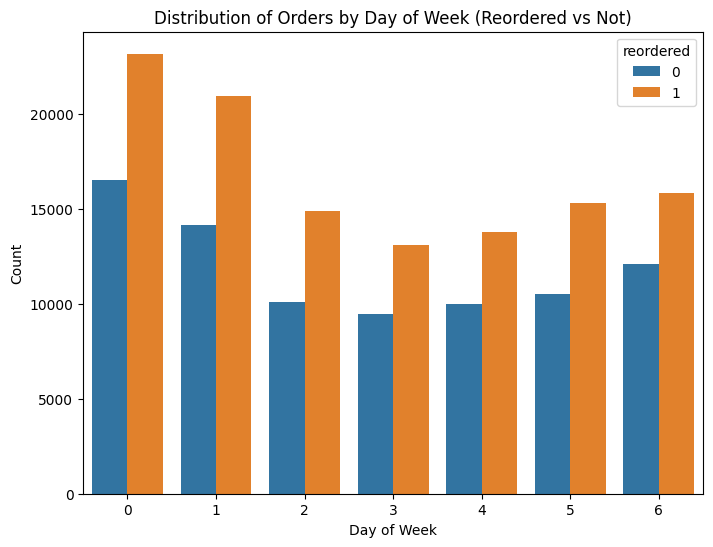

In [ ]:
# رسم العلاقة بين 'reordered' و 'order_dow'
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='order_dow', hue='reordered')
plt.title('Distribution of Orders by Day of Week (Reordered vs Not)')
plt.xlabel('Day of Week')
plt.ylabel('Count')
plt.show()


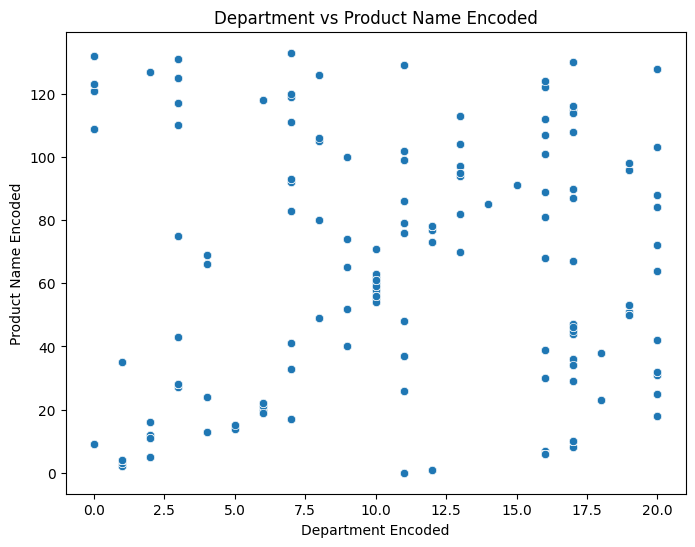

In [ ]:
# رسم العلاقة بين 'department_encoded' و 'product_name_encoded'
plt.figure(figsize=(8, 6))
sns.scatterplot(x='department_encoded', y='product_name_encoded', data=df)
plt.title('Department vs Product Name Encoded')
plt.xlabel('Department Encoded')
plt.ylabel('Product Name Encoded')
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# تقسيم البيانات
X = df[['order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order',
        'product_id', 'add_to_cart_order', 'department_id', 'department_encoded',
        'product_name_encoded']]
y = df['reordered']  # الهدف هو التنبؤ بما إذا كان سيتم إعادة الطلب

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# بناء النموذج (Random Forest)
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# التنبؤ بالنتائج
y_pred = model.predict(X_test)

# تقييم النموذج
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))


Accuracy: 0.7419
Classification Report:
               precision    recall  f1-score   support

           0       0.71      0.62      0.66     16451
           1       0.76      0.83      0.79     23549

    accuracy                           0.74     40000
   macro avg       0.74      0.72      0.73     40000
weighted avg       0.74      0.74      0.74     40000

